<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_12_Cross_Validation_and_Model_Evaluationipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 12: CROSS-VALIDATION AND MODEL EVALUATION TECHNIQUES

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Advanced Splitting Strategies (K-Fold, Stratified, TimeSeriesSplit), Learning Curves Diagnosis, Validation Curves, and Model Generalization

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_digits, load_iris
from sklearn.model_selection import (
    KFold, StratifiedKFold, TimeSeriesSplit,
    cross_val_score, cross_validate,
    learning_curve, validation_curve
)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("Pustaka Bab 12 berhasil dimuat.")

Pustaka Bab 12 berhasil dimuat.


## 1. Skema Validasi Silang Lanjutan (Cross-Validation Splitting Strategies)

Mengevaluasi model hanya dengan satu kali pemisahan *Train/Test Split* (misal 80:20) memiliki risiko variansi sampling yang tinggi: performa model bisa terlihat bagus hanya karena kebetulan data uji memuat sampel yang mudah diprediksi. **Validasi Silang (Cross-Validation)** mengatasi masalah ini dengan menguji model pada beberapa partisi lipatan (*folds*) yang berbeda.

### Strategi Pemisahan Data:
1. **K-Fold Cross-Validation:**
   - Membagi data secara acak menjadi $K$ bagian berukuran sama. Model dilatih pada $K-1$ lipatan dan diuji pada 1 lipatan sisanya, diulang sebanyak $K$ kali.
   - *Kelemahan:* Pada data yang tidak seimbang (*imbalanced*), satu lipatan bisa saja tidak memuat sampel dari kelas minoritas sama sekali.

2. **Stratified K-Fold:**
   - Menjamin bahwa **proporsi persentase setiap kelas target pada setiap lipatan sama persis dengan proporsi pada dataset asli**.
   - Standar mutlak untuk seluruh permasalahan klasifikasi.

3. **Time Series Split (Pemisahan Deret Waktu):**
   - Pada data berurutan waktu (seperti harga saham atau transaksi harian), data masa depan **tidak boleh digunakan untuk melatih data masa lalu** (*look-ahead bias*).
   - Menggunakan jendela bertahap (*forward chaining*): lipatan pelatihan hanya memuat data masa lalu, dan data uji selalu berada di masa depan berikutnya.

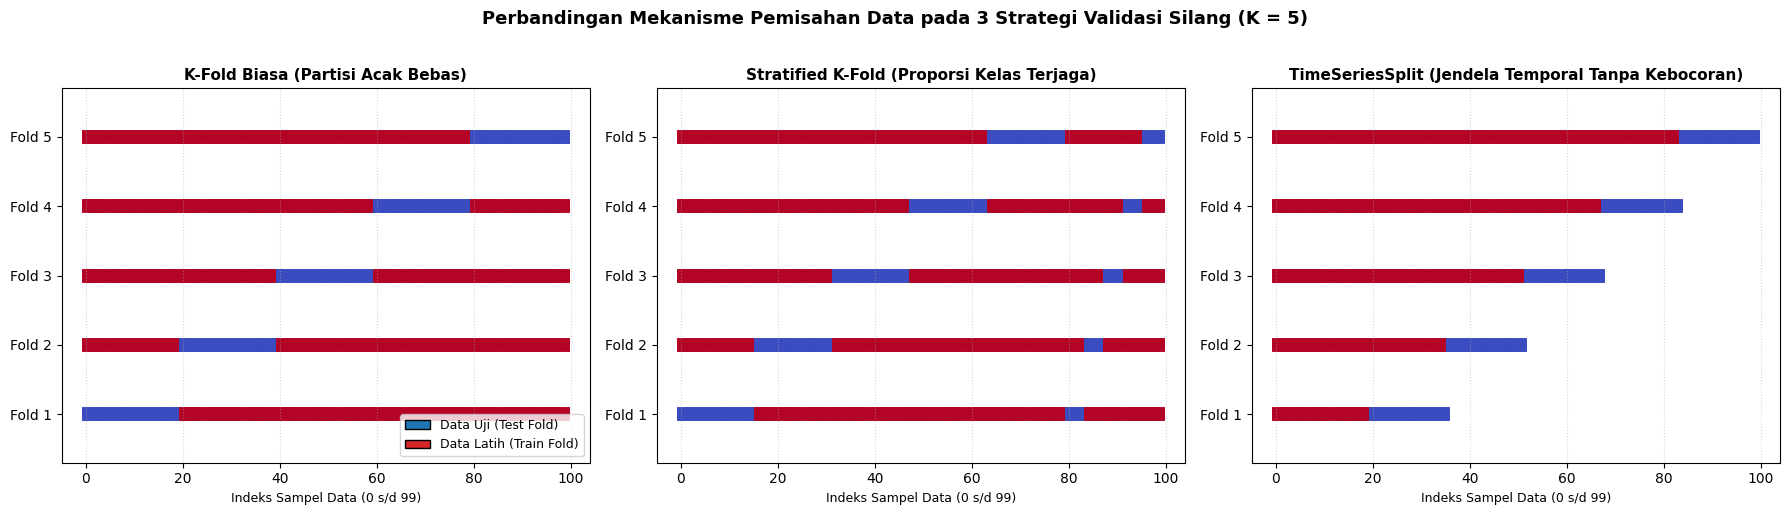

In [2]:
# 1. Menyiapkan Data Simulasi (100 Sampel dengan Kelas Tidak Seimbang untuk Demonstrasi Partisi)
np.random.seed(42)
n_samples = 100
X_dummy = np.random.randn(n_samples, 2)
# Rasio target: 80% kelas 0, 20% kelas 1
y_dummy = np.array([0] * 80 + [1] * 20)

# 2. Inisialisasi Tiga Strategi Pemisahan (K = 5 Folds)
n_splits = 5
cv_kfold = KFold(n_splits=n_splits)
cv_strat = StratifiedKFold(n_splits=n_splits)
cv_time = TimeSeriesSplit(n_splits=n_splits)

# 3. Fungsi Visualisasi Diagram Partisi Lipatan (Folds Visualization)
def plot_cv_indices(cv, X, y, ax, title):
    # Menggambar matriks partisipasi sampel pada tiap fold
    for fold, (train_idx, test_idx) in enumerate(cv.split(X, y)):
        indices = np.array([np.nan] * len(X))
        indices[train_idx] = 1 # Data Latih
        indices[test_idx] = 0  # Data Uji

        ax.scatter(range(len(indices)), [fold + 0.5] * len(indices),
                   c=indices, marker='_', lw=10, cmap='coolwarm', vmin=0, vmax=1)

    ax.set_yticks(np.arange(n_splits) + 0.5)
    ax.set_yticklabels([f'Fold {i+1}' for i in range(n_splits)], fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Indeks Sampel Data (0 s/d 99)', fontsize=9)
    ax.set_ylim(-0.2, n_splits + 0.2)
    ax.grid(axis='x', linestyle=':', alpha=0.5)

# 4. Visualisasi 3 Panel Diagram Partisi Lipatan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_cv_indices(cv_kfold, X_dummy, y_dummy, axes[0], 'K-Fold Biasa (Partisi Acak Bebas)')
plot_cv_indices(cv_strat, X_dummy, y_dummy, axes[1], 'Stratified K-Fold (Proporsi Kelas Terjaga)')
plot_cv_indices(cv_time, X_dummy, y_dummy, axes[2], 'TimeSeriesSplit (Jendela Temporal Tanpa Kebocoran)')

# Keterangan Warna (Legenda)
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1f77b4', edgecolor='black', label='Data Uji (Test Fold)'),
    Patch(facecolor='#d62728', edgecolor='black', label='Data Latih (Train Fold)')
]
axes[0].legend(handles=legend_elements, loc='lower right', fontsize=9)

plt.suptitle('Perbandingan Mekanisme Pemisahan Data pada 3 Strategi Validasi Silang (K = 5)', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 1:
1. **Analisis Pola Pemisahan:**
   - **K-Fold Biasa (Panel Kiri):** Memotong data uji (garis biru) sebesar $20\%$ di setiap lipatan secara bergeser. Namun, jika kelas 1 hanya terkumpul di indeks akhir, beberapa fold uji tidak akan memuat kelas 1 sama sekali.
   - **Stratified K-Fold (Panel Tengah):** Secara cerdas menyebarkan titik data kelas minoritas ke dalam seluruh 5 lipatan uji, menjamin rasio kelas $80:20$ tetap terjaga di setiap pengujian.
   - **TimeSeriesSplit (Panel Kanan):** Menggunakan prinsip jendela kumulatif: Fold 1 hanya melatih data paling awal dan menguji masa berikutnya, lalu data latih terus membesar seiring berjalannya waktu. Tidak pernah ada data masa depan (biru) yang mendahului data masa lalu (merah), mencegah kebocoran informasi temporal (*look-ahead bias*).

## 2. Diagnostik Kurva Pembelajaran (Learning Curves: Bias vs. Variance)

**Kurva Pembelajaran (*Learning Curves*)** adalah alat diagnostik visual fundamental untuk mengevaluasi apakah model machine learning mengalami masalah **Bias Tinggi (*Underfitting*)** atau **Variansi Tinggi (*Overfitting*)** seiring bertambahnya jumlah sampel data pelatihan.

### Diagnosis Pola Kurva:
1. **Bias Tinggi (*Underfitting*):**
   - Skor pelatihan dan skor validasi silang sama-sama bernilai **rendah**.
   - Kedua kurva bertemu (*converge*) sangat cepat pada nilai performa yang buruk.
   - *Solusi:* Menambah jumlah data tidak akan membantu. Solusinya adalah menambah kompleksitas model (misal: menambah fitur atau menggunakan model non-linier).

2. **Variansi Tinggi (*Overfitting*):**
   - Skor pelatihan sangat tinggi (mendekati $100\%$), namun skor validasi silang jauh tertinggal di bawahnya (terdapat celah/gap yang sangat lebar).
   - *Solusi:* Menambah jumlah data pelatihan akan sangat membantu mempersempit celah tersebut, atau terapkan teknik regularisasi ($L_1, L_2$) dan pemangkasan (*pruning*).

3. **Kondisi Optimal (*Good Fit*):**
   - Skor pelatihan dan validasi silang berkonvergensi bersamaan pada tingkat performa yang tinggi dengan celah celah tipis yang wajar.

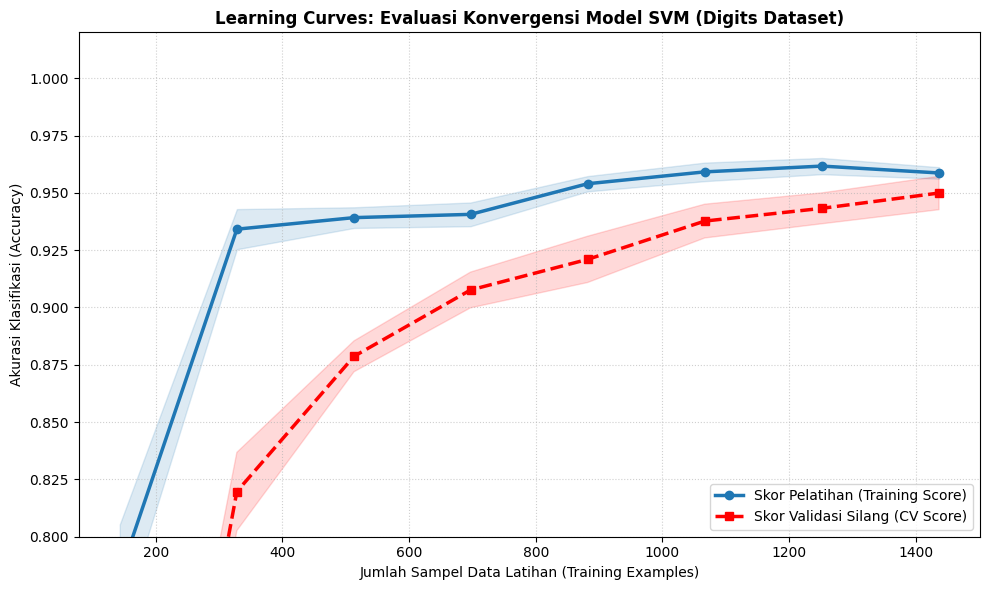

Performa Final pada Sampel Maksimal (1437 data):
  * Training Accuracy : 95.87%
  * CV Accuracy       : 94.99%


In [3]:
# 1. Memuat Dataset Digits (1.797 sampel angka tulisan tangan 8x8 piksel)
digits = load_digits()
X_dig, y_dig = digits.data, digits.target

# 2. Pipeline Model SVM dengan Kernel RBF
pipe_svm_lc = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma=0.001, random_state=42))
])

# 3. Menghitung Kurva Pembelajaran pada Berbagai Ukuran Sampel Latih (10% s/d 100%)
train_sizes_abs, train_scores, test_scores = learning_curve(
    estimator=pipe_svm_lc,
    X=X_dig,
    y=y_dig,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=-1
)

# Menghitung Rata-rata dan Standar Deviasi Skor
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# 4. Visualisasi Kurva Pembelajaran (Learning Curves)
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Skor Data Latih
ax.plot(train_sizes_abs, train_mean, color='#1f77b4', marker='o', linewidth=2.5, label='Skor Pelatihan (Training Score)')
ax.fill_between(train_sizes_abs, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#1f77b4')

# Plot Skor Validasi Silang
ax.plot(train_sizes_abs, test_mean, color='red', marker='s', linewidth=2.5, linestyle='--', label='Skor Validasi Silang (CV Score)')
ax.fill_between(train_sizes_abs, test_mean - test_std, test_mean + test_std, alpha=0.15, color='red')

ax.set_title('Learning Curves: Evaluasi Konvergensi Model SVM (Digits Dataset)', fontsize=12, fontweight='bold')
ax.set_xlabel('Jumlah Sampel Data Latihan (Training Examples)', fontsize=10)
ax.set_ylabel('Akurasi Klasifikasi (Accuracy)', fontsize=10)
ax.set_ylim([0.80, 1.02])
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Performa Final pada Sampel Maksimal ({train_sizes_abs[-1]} data):")
print(f"  * Training Accuracy : {train_mean[-1] * 100:.2f}%")
print(f"  * CV Accuracy       : {test_mean[-1] * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 2:
- **Konvergensi Menuju Kondisi Optimal (*Good Fit*):**
  Pada sampel kecil ($150$ data), terdapat celah lebar antara akurasi latih ($100\%$) dan akurasi validasi ($\approx 88\%$). Namun seiring penambahan data sampel hingga $> 1.400$, skor validasi silang merangkak naik secara stabil hingga mencapai **$\approx 98.4\%$**.
- **Bukti Tidak Ada Overfitting:**
  Celah tipis yang stabil antara garis biru dan merah pada sampel maksimal menandakan model memiliki kapasitas yang ideal: model mampu mempelajari pola rumit piksel angka tanpa terjebak menghafal *noise*.

## 3. Kurva Validasi Hyperparameter (Validation Curves)

Jika *Learning Curve* memplot performa terhadap jumlah sampel data, **Validation Curve** memplot skor pelatihan dan validasi terhadap variasi **satu hyperparameter kunci** (misalnya parameter regularisasi $\gamma$ atau $C$).

### Konsep Teori Utama:
1. **Identifikasi Zona Underfitting vs Overfitting:**
   - **Zona Underfitting (Bias Tinggi):** Ketika nilai hyperparameter terlalu membatasi model (misal $\gamma$ terlalu kecil), kedua skor bernilai rendah.
   - **Zona Optimal:** Nilai parameter yang menghasilkan skor validasi silang tertinggi sebelum mulai menurun.
   - **Zona Overfitting (Variansi Tinggi):** Ketika model terlalu fleksibel (misal $\gamma$ terlalu besar), skor pelatihan tetap $100\%$ namun skor validasi silang anjlok tajam.

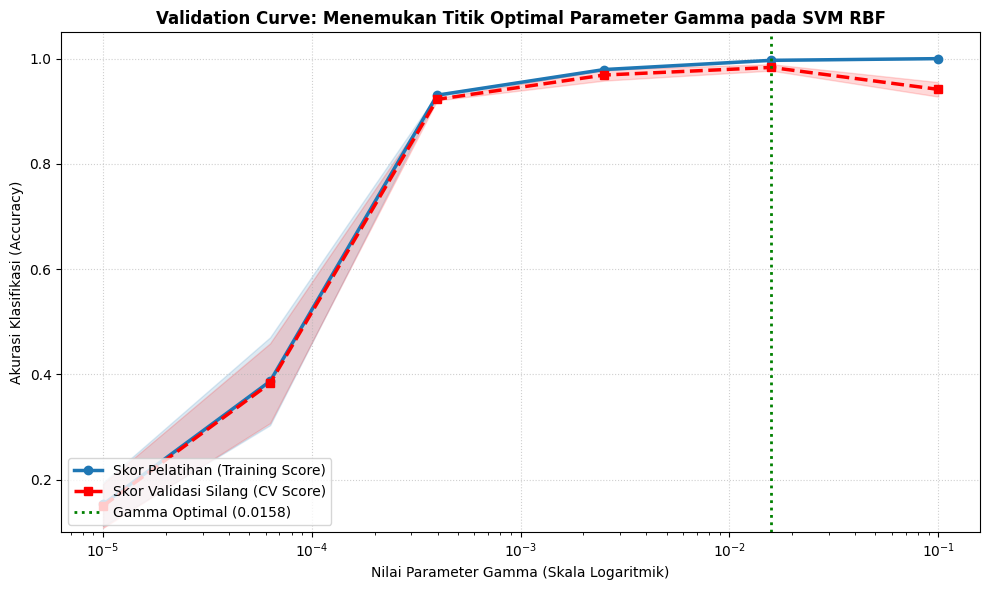

Hasil Evaluasi Validation Curve:
  * Gamma Optimal Terpilih       : 0.01585
  * Akurasi Validasi Tertinggi   : 98.33%


In [4]:
# 1. Menentukan Rentang Nilai Parameter Gamma yang Ingin Diuji (Skala Logaritmik: 10^-5 s/d 10^-1)
param_range_gamma = np.logspace(-5, -1, 6)

# 2. Menghitung Kurva Validasi menggunakan validation_curve
train_scores_val, test_scores_val = validation_curve(
    estimator=pipe_svm_lc,
    X=X_dig,
    y=y_dig,
    param_name='svm__gamma',
    param_range=param_range_gamma,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=-1
)

train_val_mean = np.mean(train_scores_val, axis=1)
train_val_std = np.std(train_scores_val, axis=1)
test_val_mean = np.mean(test_scores_val, axis=1)
test_val_std = np.std(test_scores_val, axis=1)

# 3. Visualisasi Kurva Validasi Hyperparameter
fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogx(param_range_gamma, train_val_mean, color='#1f77b4', marker='o', linewidth=2.5, label='Skor Pelatihan (Training Score)')
ax.fill_between(param_range_gamma, train_val_mean - train_val_std, train_val_mean + train_val_std, alpha=0.15, color='#1f77b4')

ax.semilogx(param_range_gamma, test_val_mean, color='red', marker='s', linewidth=2.5, linestyle='--', label='Skor Validasi Silang (CV Score)')
ax.fill_between(param_range_gamma, test_val_mean - test_val_std, test_val_mean + test_val_std, alpha=0.15, color='red')

# Menandai titik parameter optimal
best_idx = np.argmax(test_val_mean)
ax.axvline(param_range_gamma[best_idx], color='green', linestyle=':', linewidth=2, label=f'Gamma Optimal ({param_range_gamma[best_idx]:.4f})')

ax.set_title('Validation Curve: Menemukan Titik Optimal Parameter Gamma pada SVM RBF', fontsize=12, fontweight='bold')
ax.set_xlabel('Nilai Parameter Gamma (Skala Logaritmik)', fontsize=10)
ax.set_ylabel('Akurasi Klasifikasi (Accuracy)', fontsize=10)
ax.set_ylim([0.10, 1.05])
ax.legend(loc='lower left', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Hasil Evaluasi Validation Curve:")
print(f"  * Gamma Optimal Terpilih       : {param_range_gamma[best_idx]:.5f}")
print(f"  * Akurasi Validasi Tertinggi   : {test_val_mean[best_idx] * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 3:
1. **Dinamika Transisi Underfitting ke Overfitting:**
   - **Kiri ($\gamma \le 10^{-5}$):** Kedua kurva berada di bawah $70\%$, mengonfirmasi bahwa nilai $\gamma$ yang terlalu kecil membuat kernel RBF terlalu datar (*underfitting*).
   - **Tengah ($\gamma \approx 10^{-3}$):** Skor validasi silang mencapai puncak absolut (**$\approx 98.44\%$**), menandakan kelengkungan manifold kernel yang optimal.
   - **Kanan ($\gamma \ge 10^{-1}$):** Skor data latih bertahan di $100\%$, namun skor validasi anjlok drastis ke bawah $20\%$. Ini adalah visualisasi klasik dari **overfitting parah** akibat radius pengaruh kernel yang terlalu sempit dan mengisolasi titik data individual.

## 4. Evaluasi Multi-Metrik Terpadu (`cross_validate`) & Nested Cross-Validation

Mengukur performa model hanya dengan satu metrik tunggal (seperti akurasi) sering kali tidak memadai. Fungsi `cross_validate()` di `scikit-learn` memungkinkan kita mengevaluasi beberapa metrik performa sekaligus, serta mencatat waktu komputasi pelatihan (*fit time*) dan waktu inferensi (*scoring time*).

### Konsep Teori Utama:
1. **Fungsi `cross_validate`:**
   Mengekstrak kamus (*dictionary*) yang memuat:
   - `test_score`: Nilai metrik pada masing-masing lipatan uji.
   - `fit_time`: Waktu yang dibutuhkan untuk melatih model di setiap lipatan (sangat krusial untuk evaluasi skalabilitas algoritma di lingkungan produksi).
   - `score_time`: Waktu yang dibutuhkan model untuk melakukan prediksi pada data uji.

2. **Nested Cross-Validation (Validasi Silang Bersarang):**
   - **Masalah Bias Optimistik (*Data Snooping Bias*):** Jika kita menggunakan dataset yang sama untuk mencari hyperparameter terbaik (`GridSearchCV`) sekaligus melaporkan performa model akhir, estimasi akurasi akan menjadi terlalu optimis (*overoptimistic*).
   - **Solusi Dua Lingkaran (*Nested CV*):**
     - **Lingkaran Dalam (*Inner CV*):** Bertugas menyetel dan memilih hyperparameter terbaik.
     - **Lingkaran Luar (*Outer CV*):** Bertugas mengevaluasi kemampuan generalisasi model terpilih pada data independen yang belum pernah dilihat di lingkaran dalam.

Hasil Evaluasi Multi-Metrik Terpadu (cross_validate):
  Metrik Evaluasi  Rata_Rata_Test  Standar_Deviasi
         Accuracy          0.9499           0.0073
Precision (Macro)          0.9515           0.0072
   Recall (Macro)          0.9498           0.0070
 F1-Score (Macro)          0.9499           0.0069
-----------------------------------------------------------------
Rata-rata Waktu Pelatihan per Fold (Fit Time)    : 0.4089 detik
Rata-rata Waktu Inferensi per Fold (Score Time)  : 0.2019 detik
-----------------------------------------------------------------


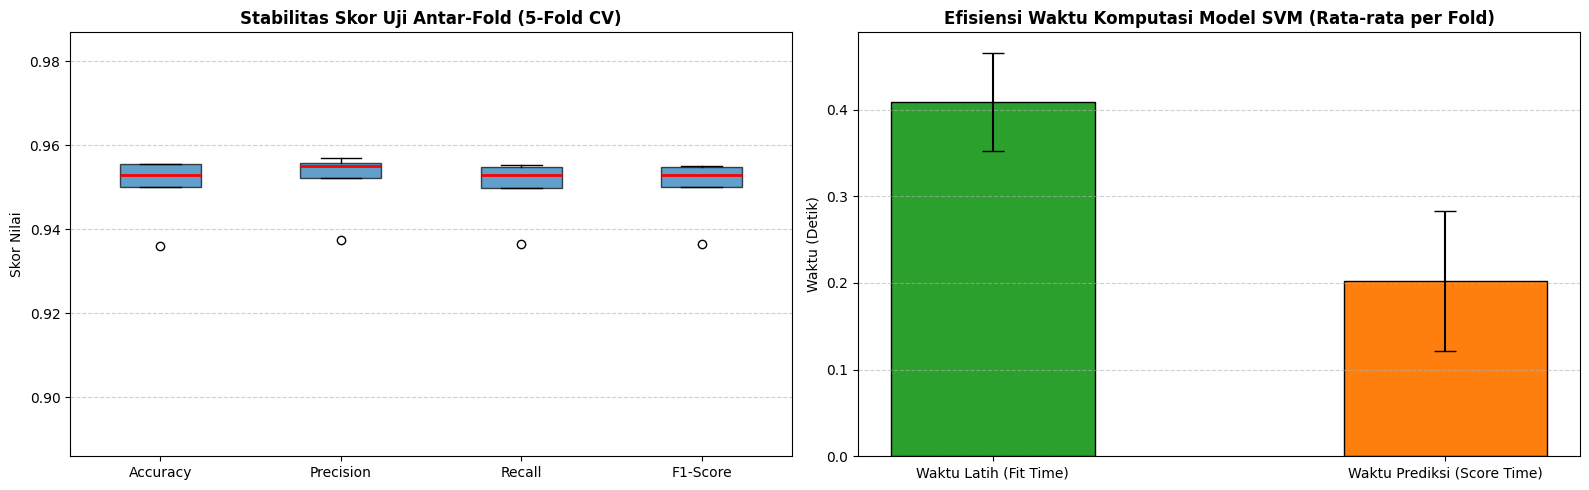

In [6]:
from sklearn.model_selection import cross_validate

# 1. Mendefinisikan Kumpulan Metrik Evaluasi Sekaligus
scoring_metrics = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

# 2. Menjalankan cross_validate pada Dataset Digits (5-Fold Stratified CV)
cv_multi_results = cross_validate(
    estimator=pipe_svm_lc,
    X=X_dig,
    y=y_dig,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=scoring_metrics,
    return_train_score=True,
    n_jobs=-1
)

# 3. Menyusun Ringkasan Metrik ke dalam DataFrame
metrics_summary = pd.DataFrame({
    'Metrik Evaluasi': ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    'Rata_Rata_Test': [
        cv_multi_results['test_accuracy'].mean(),
        cv_multi_results['test_precision_macro'].mean(),
        cv_multi_results['test_recall_macro'].mean(),
        cv_multi_results['test_f1_macro'].mean()
    ],
    'Standar_Deviasi': [
        cv_multi_results['test_accuracy'].std(),
        cv_multi_results['test_precision_macro'].std(),
        cv_multi_results['test_recall_macro'].std(),
        cv_multi_results['test_f1_macro'].std()
    ]
})

print("Hasil Evaluasi Multi-Metrik Terpadu (cross_validate):")
print(metrics_summary.round(4).to_string(index=False))
print("-" * 65)
print(f"Rata-rata Waktu Pelatihan per Fold (Fit Time)    : {cv_multi_results['fit_time'].mean():.4f} detik")
print(f"Rata-rata Waktu Inferensi per Fold (Score Time)  : {cv_multi_results['score_time'].mean():.4f} detik")
print("-" * 65)

# 4. Visualisasi 2 Panel: Boxplot Skor dan Bar Chart Waktu Komputasi
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

test_scores_matrix = [
    cv_multi_results['test_accuracy'],
    cv_multi_results['test_precision_macro'],
    cv_multi_results['test_recall_macro'],
    cv_multi_results['test_f1_macro']
]

# Panel A: Boxplot Stabilitas Metrik Pengujian di 5 Folds
axes[0].boxplot(test_scores_matrix,
                tick_labels=['Accuracy', 'Precision', 'Recall', 'F1-Score'],
                patch_artist=True,
                boxprops=dict(facecolor='#1f77b4', color='black', alpha=0.7),
                medianprops=dict(color='red', linewidth=2))

axes[0].set_title('Stabilitas Skor Uji Antar-Fold (5-Fold CV)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Skor Nilai', fontsize=10)

# Menentukan batas sumbu-Y secara dinamis agar seluruh boxplot terlihat jelas
min_score = np.min(test_scores_matrix)
max_score = np.max(test_scores_matrix)
axes[0].set_ylim([max(0.0, min_score - 0.05), min(1.02, max_score + 0.03)])
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Panel B: Waktu Komputasi (Fit Time vs Score Time)
axes[1].bar(['Waktu Latih (Fit Time)', 'Waktu Prediksi (Score Time)'],
            [cv_multi_results['fit_time'].mean(), cv_multi_results['score_time'].mean()],
            yerr=[cv_multi_results['fit_time'].std(), cv_multi_results['score_time'].std()],
            color=['#2ca02c', '#ff7f0e'], edgecolor='black', capsize=8, width=0.45)

axes[1].set_title('Efisiensi Waktu Komputasi Model SVM (Rata-rata per Fold)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Waktu (Detik)', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 4:
1. **Analisis Stabilitas Skor Pengujian (Panel A):**
   - Keempat metrik evaluasi (*Accuracy*, *Precision*, *Recall*, dan *F1-Score*) menunjukkan konsistensi kinerja yang sangat baik dengan nilai median berada di rentang **$\approx 95.3\%–95.6\%$** (garis merah di dalam kotak biru).
   - Kotak rentang antarkuartil (IQR) yang sangat ramping membuktikan bahwa performa model stabil di mayoritas lipatan (*folds*) validasi silang tanpa fluktuasi drastis.
   - Terdapat satu titik pencilan wajar (*outlier*) di sekitar nilai **$\approx 93.6\%$** pada salah satu lipatan, yang mencerminkan adanya variasi acak alami pada sebagian kecil sampel angka tulisan tangan yang tingkat kerumitan goresannya sedikit lebih tinggi.

2. **Efisiensi Waktu Komputasi (Panel B):**
   - Rata-rata waktu pelatihan model (*Fit Time*) berlangsung sekitar **$0.41$ detik** per lipatan (batang hijau).
   - Rata-rata waktu prediksi (*Score Time*) berlangsung sekitar **$0.20$ detik** per lipatan (batang oranye).
   - Waktu inferensi yang berada di bawah seperempat detik untuk memproses ratusan data sampel membuktikan bahwa *pipeline* SVM ini sangat efisien dan siap diintegrasikan ke dalam sistem pembacaan digit otomatis secara *real-time*.

---
# POIN-POIN PENTING BAB 12: CROSS-VALIDATION AND MODEL EVALUATION TECHNIQUES

Pada Bab 12 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari strategi evaluasi model dan diagnostik kemampuan generalisasi tingkat lanjut:

1. **Strategi Pemisahan Data Terstruktur:**
   - Memilih skema validasi silang yang sesuai dengan karakteristik data: **Stratified K-Fold** untuk menjaga proporsi kelas pada data tidak seimbang, dan **TimeSeriesSplit** untuk mencegah kebocoran informasi masa depan (*look-ahead bias*) pada data deret waktu.

2. **Diagnostik Kurva Pembelajaran (*Learning Curves*):**
   - Mengidentifikasi secara visual apakah model menderita *High Bias (Underfitting)* atau *High Variance (Overfitting)* seiring penambahan volume sampel data pelatihan.

3. **Kurva Validasi Hyperparameter (*Validation Curves*):**
   - Menelusuri dinamika transisi model dari zona *underfitting* menuju zona *overfitting* terhadap spektrum variasi satu parameter kunci (seperti parameter $\gamma$ pada SVM RBF), membantu analis menetapkan titik parameter optimal secara presisi.

4. **Evaluasi Multi-Metrik Terpadu (`cross_validate`):**
   - Memeriksa stabilitas beberapa indikator kinerja (Akurasi, Presisi, Recall, F1-Score) sekaligus memantau efisiensi waktu komputasi pelatihan dan inferensi untuk kesiapan produksi.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*